In [1]:
import numpy as np
import scipy as sp
from src.data import DataLoader
from src.timescales import Timescales

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset = 'HCP-YA'
data_loader = DataLoader(dataset=dataset)

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Raw data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/derivatives
Output directory: /home/lindenmp/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects


In [3]:
# subject_ids = data_loader.df_behavior.index.astype(str).tolist()[:20]  # First 10 subjects
# subject_ids = ['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', 
#                '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', 
#                '103212', '103414', '103515', '103818']
subject_ids = ['102816', ]
            #    '100610', '102311', '102816', '104416', '105923', '108323', '109123', '111514', '114823', '115017']
            #    '115825', '116726', '118225', '125525', '126426', '128935', '130114', '130518', '131217', '131722']
subject_ids

['102816']

In [4]:
# Register 3T REST scans
rest_scans = data_loader.register_3t_rest_scans(
    subject_ids=subject_ids,
    atlas='Schaefer4007',
    sessions=[1, 2],
    phase_encodings=['LR', 'RL']
)

# Load the data
rest_data = data_loader.load_batch(
    modalities=['MRI3T'],
    conditions=['rest'],
    verbose=True
)

print(f"Loaded {len(rest_data)} scans")
# data_loader.clear_cache()

print(rest_data.keys())

Loading 4 scans...
  [1/4] 102816 rfMRIREST1LR

Loaded: 4/4 scans
Loaded 4 scans
dict_keys(['sub-102816_modality-MRI3T_scan-rfMRIREST1LR_atlas-Schaefer4007', 'sub-102816_modality-MRI3T_scan-rfMRIREST1RL_atlas-Schaefer4007', 'sub-102816_modality-MRI3T_scan-rfMRIREST2LR_atlas-Schaefer4007', 'sub-102816_modality-MRI3T_scan-rfMRIREST2RL_atlas-Schaefer4007'])


In [5]:
# =========================
meg_scans = data_loader.register_meg_scans(
    subject_ids=subject_ids,
    atlas='Schaefer4007',
    rest_runs=[3, 4, 5],
    wm_runs=[6, 7]
)

meg_data = data_loader.load_batch(
    modalities=['MEG'],
    nuisance_regression=False,
    verbose=True
)

print(meg_data.keys())

Loading 5 scans...
  [1/5] 102816 3-Restin

Loaded: 5/5 scans
dict_keys(['sub-102816_modality-MEG_scan-3-Restin_atlas-Schaefer4007', 'sub-102816_modality-MEG_scan-4-Restin_atlas-Schaefer4007', 'sub-102816_modality-MEG_scan-5-Restin_atlas-Schaefer4007', 'sub-102816_modality-MEG_scan-6-Wrkmem_atlas-Schaefer4007', 'sub-102816_modality-MEG_scan-7-Wrkmem_atlas-Schaefer4007'])


<Axes: >

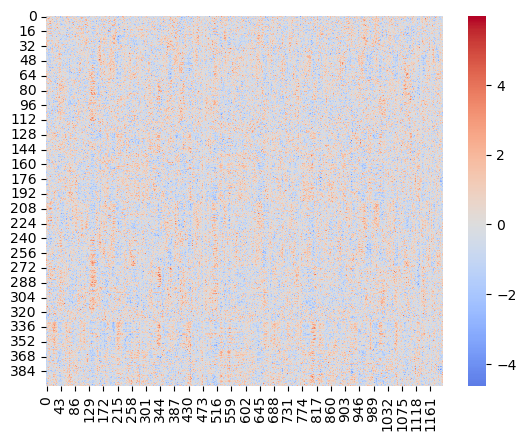

In [6]:
sns.heatmap(rest_data['sub-102816_modality-MRI3T_scan-rfMRIREST1LR_atlas-Schaefer4007'], cmap='coolwarm', center=0)
# sns.heatmap(meg_data['102816_MEG_3-Restin_Schaefer4007'], cmap='coolwarm', center=0)

In [7]:
data_loader.summary()


Dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Output directory: /home/lindenmp/intrinsic_neural_timescales
Registered scans: 9

Scans by modality:
modality
MEG      5
MRI3T    4
Name: count, dtype: int64

Scans by condition:
condition
rest    7
task    2
Name: count, dtype: int64

Behavioral data: (1206, 584)

Cache: 9 scans, 1882.1 MB



In [8]:
timescales_processor = Timescales(dataset=dataset, timeseries_data=meg_data, modality='MEG')

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Raw data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/derivatives
Output directory: /home/lindenmp/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Modality: MEG
	TR: 0.0019660657059158916
	Number of scans: 5
	Output directory: /home/lindenmp/intrinsic_neural_timescales


In [9]:
freq_windows = [
    # (0, 4),  # up to delta limit
    (0, 7),  # up to theta limit
    (0, 12),  # up to alpha limit
    (0, 29),  # up to beta limit
    (0, 60),  # up to low gamma limit
    None,
]

In [10]:
# for freq_window in freq_windows:
#     print(freq_window)

#     timescales_processor.compute_autocorrelation_function(use_fft=True, freq_window=freq_window)

(0, 7)


Computing autocorrelation: 100%|██████████| 5/5 [00:01<00:00,  3.88it/s]



Autocorrelation computation complete:
  Loaded from cache: 5
  Newly computed: 0
  Total: 5


Computing auc_100 timescales: 100%|██████████| 5/5 [00:00<00:00, 796.76it/s]


auc_100 timescale computation complete:
  Loaded from cache: 0
  Newly computed: 5
  Total: 5


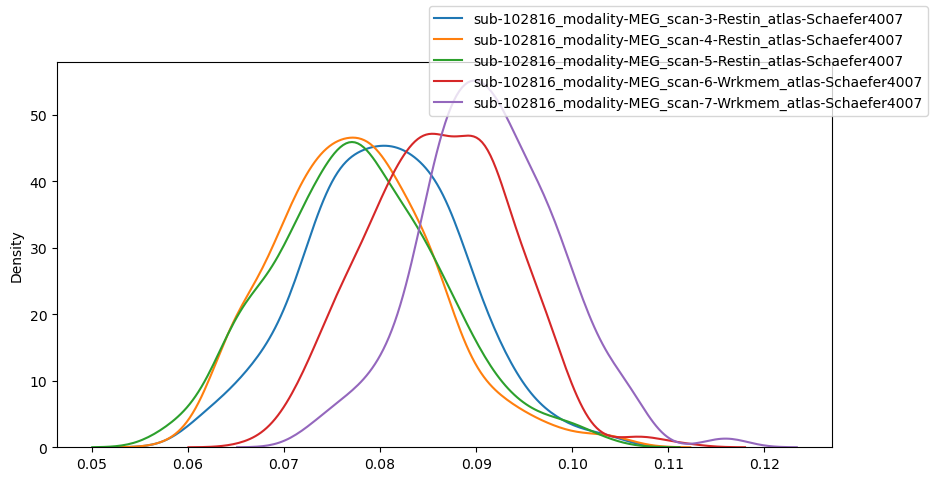

(0, 12)


Computing autocorrelation: 100%|██████████| 5/5 [00:01<00:00,  3.74it/s]



Autocorrelation computation complete:
  Loaded from cache: 5
  Newly computed: 0
  Total: 5


Computing auc_100 timescales: 100%|██████████| 5/5 [00:00<00:00, 786.04it/s]


auc_100 timescale computation complete:
  Loaded from cache: 0
  Newly computed: 5
  Total: 5


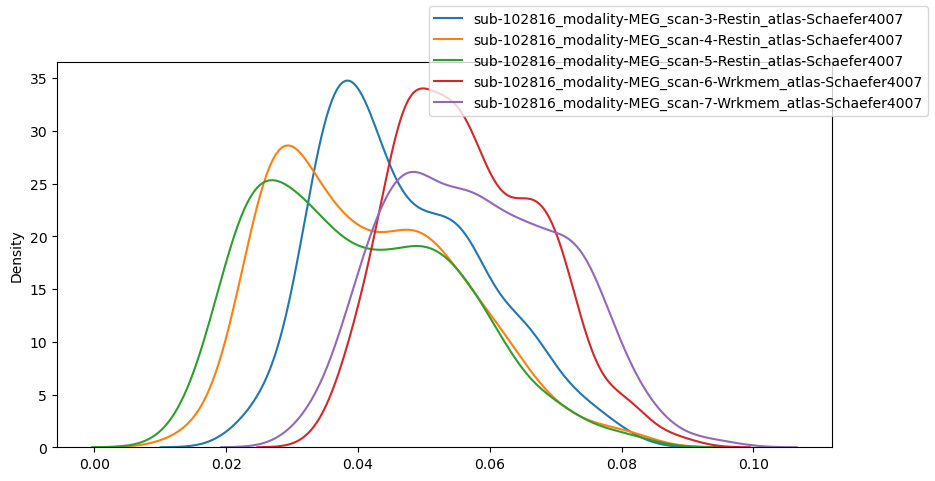

(0, 29)


Computing autocorrelation: 100%|██████████| 5/5 [00:01<00:00,  3.66it/s]



Autocorrelation computation complete:
  Loaded from cache: 5
  Newly computed: 0
  Total: 5


Computing auc_100 timescales: 100%|██████████| 5/5 [00:00<00:00, 789.53it/s]


auc_100 timescale computation complete:
  Loaded from cache: 0
  Newly computed: 5
  Total: 5


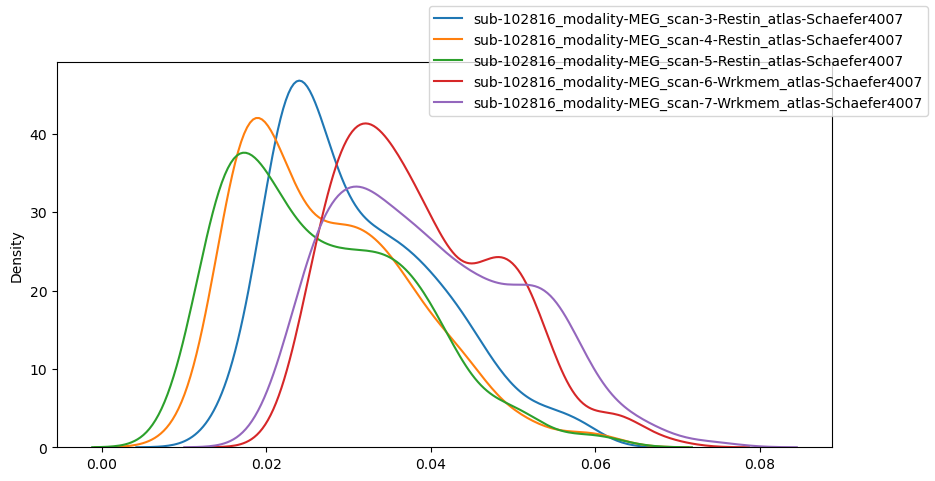

(0, 60)


Computing autocorrelation: 100%|██████████| 5/5 [00:01<00:00,  3.66it/s]



Autocorrelation computation complete:
  Loaded from cache: 5
  Newly computed: 0
  Total: 5


Computing auc_100 timescales: 100%|██████████| 5/5 [00:00<00:00, 722.83it/s]


auc_100 timescale computation complete:
  Loaded from cache: 0
  Newly computed: 5
  Total: 5


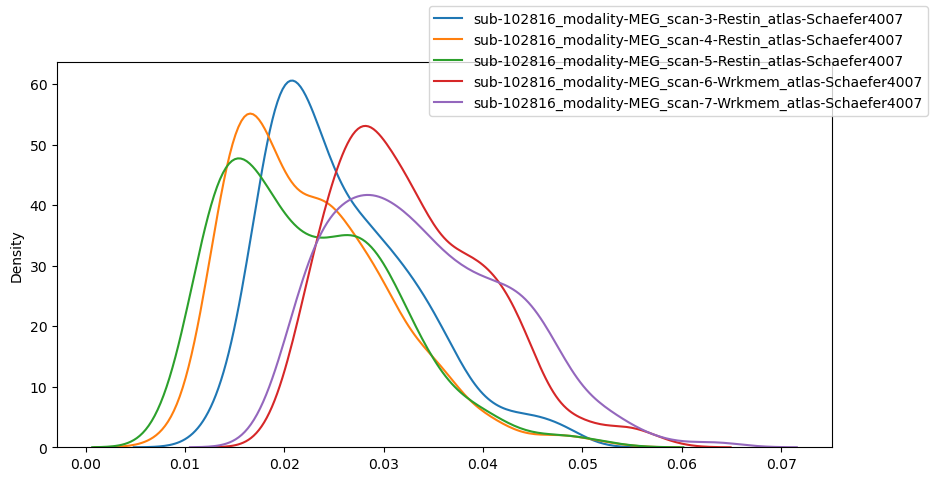

None


Computing autocorrelation: 100%|██████████| 5/5 [00:01<00:00,  3.86it/s]



Autocorrelation computation complete:
  Loaded from cache: 5
  Newly computed: 0
  Total: 5


Computing auc_100 timescales: 100%|██████████| 5/5 [00:00<00:00, 786.98it/s]


auc_100 timescale computation complete:
  Loaded from cache: 0
  Newly computed: 5
  Total: 5


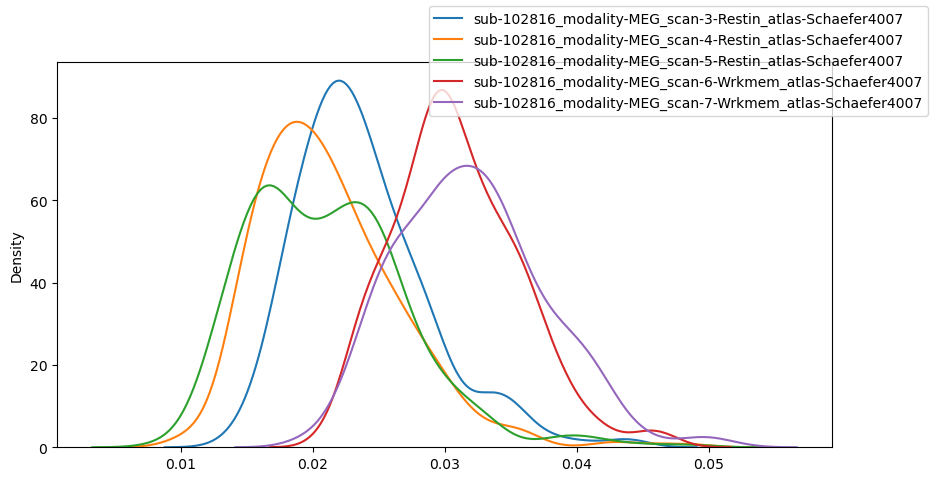

In [12]:
for freq_window in freq_windows:
    print(freq_window)
    timescales_processor.compute_autocorrelation_function(use_fft=True, freq_window=freq_window)
    autocorr_dict = timescales_processor.autocorr_dict

    # fig, axes = plt.subplots(1, 1, figsize=(10, 2.5))
    # for scan in autocorr_dict.keys():
    #     # print(scan, autocorr_dict[scan].shape)
    #     plt.plot(autocorr_dict[scan].mean(axis=0)[:150], label=scan)
    #     # plt.plot(autocorr_dict[scan][0, :150], label=scan)
    # plt.axhline(y=0, linestyle=':', color='gray')
    # fig.legend()
    # plt.show()
    
    timescales_processor.compute_timescale_measures(method='auc_100', save_outputs=False, force_recompute=True)
    timescales_dict = timescales_processor.timescales_dict

    fig, axes = plt.subplots(1, 1, figsize=(10, 5))
    for scan in autocorr_dict.keys():
        # print(scan, autocorr_dict[scan].shape)
        sns.kdeplot(timescales_dict[scan], label=scan)
    fig.legend()
    plt.show()